# Lecture 7: The Armington hypothesis

The seventh model lets a country import and export the same good. The sixth notebook treated domestic and foreign goods as the same product, so each good was either imported or exported. Here each good comes in a domestic and an imported variety, which buyers combine in a CES aggregate, after Armington (1969). Producers split their output between the domestic market and exports along a CET frontier.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [Computable General Equilibrium Model: the Armington hypothesis](https://www.youtube.com/watch?v=HqvVdhe0WAs)
- ✅ Correction: [The Armington hypothesis, correction](https://www.youtube.com/watch?v=aEhRgx0vgbA)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cge_modeling as cm

## The economy

Trade data show two-way trade within sectors. The lecture's example is Kenya in 2017, which exported 1,701 and imported 6,498 million USD of industrial goods, according to WITS. If domestic and foreign goods were the same product, only the cheaper source would sell, and two-way trade could not happen. Armington (1969) treats goods as differentiated by their country of origin.

Production, household income and the government's spending rules are unchanged from the sixth notebook. Three blocks replace its trade equations.

- Absorption $DEMTOT_i$ is the total household, government, investment and intermediate demand for good $i$. It is a CES aggregate of the domestic variety $D_i$ and imports $M_i$, with price $PDEMTOT_i$. Cost minimization gives $D_i = a^D_i \cdot DEMTOT_i \cdot \left(\frac{PDEMTOT_i}{PD_i}\right)^{\sigma^{arm}_i}$ and $M_i = a^M_i \cdot DEMTOT_i \cdot \left(\frac{PDEMTOT_i}{PM_i}\right)^{\sigma^{arm}_i}$.
- Each sector splits its output $Y_i$ between domestic sales $XD_i$ and exports $X_i$ along a CET frontier with price $PY_i$. Revenue maximization gives $XD_i = a^{XD}_i \cdot Y_i \cdot \left(\frac{PD_i}{PY_i}\right)^{\sigma^{cet}_i}$ and $X_i = a^X_i \cdot Y_i \cdot \left(\frac{PX_i}{PY_i}\right)^{\sigma^{cet}_i}$.
- Imports and exports have separate world prices, $PWM_i$ and $PWX_i$. The country is large, so the rest of the world supplies imports along $M_i = f^M_i \cdot PWM_i^{\sigma^M_i}$ and buys exports along $X_i = f^X_i \cdot PWX_i^{-\sigma^X_i}$.

The domestic variety is sold only at home, so domestic sales equal domestic demand, $XD_i = D_i$. The numeraire is the domestic price of agriculture, $PD_{Agr}$, and the check variable $Leon$ moves back to the labor market.

### Variables

Eleven variables are new: absorption and its price, the domestic variety and its price, domestic sales, and imports and exports with their domestic and world prices. The excess demand $ED_i$ and the single world price $pe_i$ of the sixth notebook are gone.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
mod = cm.CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Labor demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Consumer price of good <dim:i>")
    PY = cm.Variable("PY", dims="i", description="Producer price of the output of sector <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    DEMTOT = cm.Variable("DEMTOT", dims="i", description="Absorption of good <dim:i>")
    PDEMTOT = cm.Variable("PDEMTOT", dims="i", description="Price of absorption of good <dim:i> before tax")
    D = cm.Variable("D", dims="i", description="Domestic variety of good <dim:i> bought at home")
    PD = cm.Variable("PD", dims="i", description="Domestic price of good <dim:i>")
    XD = cm.Variable("XD", dims="i", description="Domestic sales of sector <dim:i>")
    M = cm.Variable("M", dims="i", description="Imports of good <dim:i>")
    PM = cm.Variable("PM", dims="i", description="Domestic price of imports of good <dim:i>")
    X = cm.Variable("X", dims="i", description="Exports of good <dim:i>")
    PX = cm.Variable("PX", dims="i", description="Domestic price of exports of good <dim:i>")
    PWM = cm.Variable("PWM", dims="i", description="World price of imports of good <dim:i>")
    PWX = cm.Variable("PWX", dims="i", description="World price of exports of good <dim:i>")
    W = cm.Variable("W", description="Wage")
    R = cm.Variable("R", description="Return to capital")
    INC = cm.Variable("INC", description="Gross income of households")
    DISP_INC = cm.Variable("DISP_INC",
                           latex_name=r"\mathrm{DISP\_INC}",
                           description="Disposable income of households")
    savings = cm.Variable("savings", description="Household saving")
    C = cm.Variable("C", dims="i", description="Household consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of households")
    BUDG_EXP = cm.Variable("BUDG_EXP",
                           latex_name=r"\mathrm{BUDG\_EXP}",
                           description="Government spending")
    CG = cm.Variable("CG", dims="i", description="Government purchases of good <dim:i>")
    INV = cm.Variable("INV", description="Total investment")
    CK = cm.Variable("CK", dims="i", description="Investment demand for good <dim:i>")
    tradesold = cm.Variable("tradesold", description="Trade balance, exports minus imports")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

<IPython.core.display.Latex object>

### Parameters

The new parameters are the share parameters of the Armington and CET functions, the scales $f^M_i$ and $f^X_i$ of the rest of the world's supply and demand curves, and four elasticities. $\sigma^{arm}_i$ is the elasticity of substitution between the domestic and imported varieties, and $\sigma^{cet}_i$ the elasticity of transformation between domestic sales and exports. $\sigma^M_i$ and $\sigma^X_i$ are the price elasticities of the rest of the world's import supply and export demand. The exchange rate $e$ is fixed at 1, as in the sixth notebook.

In [3]:
with mod:
    alpha = cm.Parameter("alpha", dims="i", description="Capital share of value added in sector <dim:i>")
    A = cm.Parameter("A", dims="i", description="Productivity in sector <dim:i>")
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    gamma = cm.Parameter("gamma", dims="i", description="Household budget share of good <dim:i>")
    alpha_g = cm.Parameter("alpha_g",
                           dims="i",
                           latex_name=r"\alpha^G",
                           description="Government budget share of good <dim:i>")
    alpha_k = cm.Parameter("alpha_k",
                           dims="i",
                           latex_name=r"\alpha^K",
                           description="Investment budget share of good <dim:i>")
    mps = cm.Parameter("mps", description="Marginal propensity to save")
    itr = cm.Parameter("itr", description="Income tax rate")
    tau = cm.Parameter("tau", dims="i", description="Indirect tax rate on absorption of good <dim:i>")
    tm = cm.Parameter("tm", dims="i", description="Import duty rate on good <dim:i>")
    a_d = cm.Parameter("a_d",
                       dims="i",
                       latex_name="a^D",
                       description="Share parameter of the domestic variety of good <dim:i>")
    a_m = cm.Parameter("a_m",
                       dims="i",
                       latex_name="a^M",
                       description="Share parameter of imports of good <dim:i>")
    a_xd = cm.Parameter("a_xd",
                        dims="i",
                        latex_name="a^{XD}",
                        description="Share parameter of domestic sales of sector <dim:i>")
    a_x = cm.Parameter("a_x",
                       dims="i",
                       latex_name="a^X",
                       description="Share parameter of exports of sector <dim:i>")
    sigma_arm = cm.Parameter("sigma_arm",
                             dims="i",
                             latex_name=r"\sigma^{arm}",
                             description="Elasticity of substitution between domestic and imported good <dim:i>")
    sigma_cet = cm.Parameter("sigma_cet",
                             dims="i",
                             latex_name=r"\sigma^{cet}",
                             description="Elasticity of transformation between domestic sales and exports of sector <dim:i>")
    f_m = cm.Parameter("f_m",
                       dims="i",
                       latex_name="f^M",
                       description="Scale of the rest of the world's supply of good <dim:i>")
    f_x = cm.Parameter("f_x",
                       dims="i",
                       latex_name="f^X",
                       description="Scale of the rest of the world's demand for good <dim:i>")
    sigma_m = cm.Parameter("sigma_m",
                           dims="i",
                           latex_name=r"\sigma^M",
                           description="Price elasticity of the rest of the world's supply of good <dim:i>")
    sigma_x = cm.Parameter("sigma_x",
                           dims="i",
                           latex_name=r"\sigma^X",
                           description="Price elasticity of the rest of the world's demand for good <dim:i>")
    e = cm.Parameter("e", description="Exchange rate")
    pubsold = cm.Parameter("pubsold", description="Public balance, revenue minus spending")
    LS = cm.Parameter("LS", description="Labor supply")
    KS = cm.Parameter("KS", description="Capital supply")
    PD_Agr = cm.Parameter("PD_Agr",
                          latex_name=r"\bar{PD}_{Agr}",
                          description="Domestic price of agriculture, the numeraire")

mod.summary("parameters")

<IPython.core.display.Latex object>

### Equations

The production block is unchanged, but the zero-profit condition now values output at $PY_i$, the price of the CET aggregate. The Armington and CET blocks each have a value identity, $PDEMTOT_i \cdot DEMTOT_i = PD_i \cdot D_i + PM_i \cdot M_i$ and $PY_i \cdot Y_i = PD_i \cdot XD_i + PX_i \cdot X_i$, and the two demands or supplies above.

The indirect tax now falls on absorption, $PDEMTOT_i \cdot (1 + \tau_i) = P_i$, so the government collects $\tau_i \cdot PDEMTOT_i \cdot DEMTOT_i$. The import duty applies to imports at world prices, $PM_i = e \cdot PWM_i \cdot (1 + tm_i)$. There is no export tax, so $PX_i = e \cdot PWX_i$. The trade balance values exports and imports at their own world prices, and the macroeconomic balance sets household and public saving less investment equal to it.

In [4]:
with mod:
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", PY * Y, PVA * VA + PIC * IC)
    cm.Equation("Value added production", VA, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", R * KD, alpha * PVA * VA)
    cm.Equation("Labor demand", W * LD, (1 - alpha) * PVA * VA)
    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))

    cm.Equation("Output value", PY * Y, PD * XD + PX * X)
    cm.Equation("Domestic supply", PD * XD, PD * a_xd * Y * (PD / PY) ** sigma_cet)
    cm.Equation("Export supply", PX * X, PX * a_x * Y * (PX / PY) ** sigma_cet)

    cm.Equation("Absorption", DEMTOT, C + CG + CK + CIJ.sum("j"))
    cm.Equation("Absorption value", PDEMTOT * DEMTOT, PD * D + PM * M)
    cm.Equation("Domestic demand", PD * D, PD * a_d * DEMTOT * (PDEMTOT / PD) ** sigma_arm)
    cm.Equation("Import demand", PM * M, PM * a_m * DEMTOT * (PDEMTOT / PM) ** sigma_arm)
    cm.Equation("Domestic market clearing", XD, D)

    cm.Equation("Tax wedge", PDEMTOT * (1 + tau), P)
    cm.Equation("Import price", PM, e * PWM * (1 + tm))
    cm.Equation("Export price", PX, e * PWX)
    cm.Equation("Import supply", M, f_m * PWM**sigma_m)
    cm.Equation("Export demand", X, f_x * PWX ** (-sigma_x))

    cm.Equation("Income", INC, W * LS + R * KS)
    cm.Equation("Disposable income", DISP_INC, (1 - itr) * INC)
    cm.Equation("Saving", savings, mps * DISP_INC)
    cm.Equation("Consumption", P * C, gamma * (1 - mps) * DISP_INC)
    cm.Equation("Utility", U, (C**gamma).prod())
    cm.Equation("Investment demand", P * CK, alpha_k * INV)
    cm.Equation("Public balance",
                pubsold,
                itr * INC + (tau * PDEMTOT * DEMTOT).sum() + (tm * e * PWM * M).sum() - BUDG_EXP)
    cm.Equation("Government demand", P * CG, alpha_g * BUDG_EXP)
    cm.Equation("Trade balance", tradesold, e * (PWX * X - PWM * M).sum())

    cm.Equation("Labor market clearing", LS, LD.sum() + Leon)
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Macroeconomic balance", savings - INV + pubsold, tradesold)
    cm.Equation("Numeraire", PD.sel(i="Agr"), PD_Agr)

mod.equation_table()

<IPython.core.display.Latex object>

In [5]:
mod.compile();

Compiling a model with 88 equations, 88 variables, 73 parameters


## Data

The lecture's SAM, which the slide labels as fake data, has separate commodity and activity accounts. The version below merges them, as the course program does. Every good is now both imported and exported. The `RoW` row records imports at world prices, 150, 430 and 90, and the `RoW` column records exports, 350, 30 and 100. The `RoW` column also pays 190 into the saving account `Inv`, the trade deficit financed by foreign saving.

As in the sixth notebook, the 1320 that industry pays the government includes 300 of import duty, so the duties enter as data of their own. All four elasticities equal 3 for every good.

In [6]:
accounts = ["LD", "KD", "Hld", "Gvt", *sectors, "Inv", "RoW"]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["LD", sectors] = [1100.0, 1700.0, 4150.0]
sam.loc["KD", sectors] = [250.0, 1800.0, 550.0]
sam.loc["Hld", ["LD", "KD"]] = [6950.0, 2600.0]
sam.loc["Gvt", ["Hld", *sectors]] = [1400.0, 150.0, 1320.0, 280.0]
sam.loc[sectors, "Hld"] = [1700.0, 1200.0, 3400.0]
sam.loc[sectors, "Gvt"] = [400.0, 900.0, 2750.0]
sam.loc[sectors, "Inv"] = [200.0, 800.0, 140.0]
sam.loc[sectors, "RoW"] = [350.0, 30.0, 100.0]
sam.loc[sectors, sectors] = [[1120.0, 930.0, 1100.0],
                             [2200.0, 3120.0, 3300.0],
                             [830.0, 2250.0, 1100.0]]
sam.loc["Inv", ["Hld", "Gvt", "RoW"]] = [1850.0, -900.0, 190.0]
sam.loc["RoW", sectors] = [150.0, 430.0, 90.0]

import_duties = pd.Series([0.0, 300.0, 0.0], index=sectors)
elasticities = pd.DataFrame(3.0,
                            index=sectors,
                            columns=["sigma_arm", "sigma_cet", "sigma_m", "sigma_x"])

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,LD,KD,Hld,Gvt,Agr,Ind,Serv,Inv,RoW
LD,0.0,0.0,0.0,0.0,1100.0,1700.0,4150.0,0.0,0.0
KD,0.0,0.0,0.0,0.0,250.0,1800.0,550.0,0.0,0.0
Hld,6950.0,2600.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Gvt,0.0,0.0,1400.0,0.0,150.0,1320.0,280.0,0.0,0.0
Agr,0.0,0.0,1700.0,400.0,1120.0,930.0,1100.0,200.0,350.0
Ind,0.0,0.0,1200.0,900.0,2200.0,3120.0,3300.0,800.0,30.0
Serv,0.0,0.0,3400.0,2750.0,830.0,2250.0,1100.0,140.0,100.0
Inv,0.0,0.0,1850.0,-900.0,0.0,0.0,0.0,0.0,190.0
RoW,0.0,0.0,0.0,0.0,150.0,430.0,90.0,0.0,0.0


## Calibration

The calibration follows the course program line by line, so that the results match the correction. Every price starts at 1, and the program then derives three of them. Output $Y_{0,i}$ is a goods column's total less its imports and import duty, so it includes the indirect tax. The producer price $PY_{0,i}$ follows from the zero-profit condition, and domestic sales are the value of output less exports, $XD_{0,i} = PY_{0,i} \cdot Y_{0,i} - X_{0,i}$. Absorption is priced net of the indirect tax, $PDEMTOT_{0,i} = \frac{1}{1 + \tau_i}$. The import price is whatever closes the absorption value identity:

$$PM_{0,i} = \frac{PDEMTOT_{0,i} \cdot DEMTOT_{0,i} - PD_{0,i} \cdot D_{0,i}}{M_{0,i}}.$$

The import price therefore moves away from 1, and some benchmark values differ from the SAM. Industry's duty rate is $\frac{300}{PM_{0,Ind} \cdot M_{0,Ind} - 300}$, and the public and trade balances come from the model's equations instead of the SAM.

Each share parameter is a benchmark quantity ratio times a relative price raised to minus its elasticity, for example $a^M_i = \frac{M_{0,i}}{DEMTOT_{0,i}} \cdot \left(\frac{PDEMTOT_{0,i}}{PM_{0,i}}\right)^{-\sigma^{arm}_i}$. The scales $f^M_i$ and $f^X_i$ follow from benchmark trade and world prices.

In [7]:
def calibrate_model(mod, sam, import_duties, elasticities):
    LD = sam.loc["LD", sectors].values
    KD = sam.loc["KD", sectors].values
    CIJ = sam.loc[sectors, sectors].values
    C = sam.loc[sectors, "Hld"].values
    CG = sam.loc[sectors, "Gvt"].values
    CK = sam.loc[sectors, "Inv"].values
    IMPDUTY = import_duties.values
    INDTAX = sam.loc["Gvt", sectors].values - IMPDUTY
    DIRTAX = sam.loc["Gvt", "Hld"]
    savings = sam.loc["Inv", "Hld"]
    M = sam.loc["RoW", sectors].values + IMPDUTY
    X = sam.loc[sectors, "RoW"].values
    Y = sam[sectors].sum(axis=0).values - sam.loc["RoW", sectors].values - IMPDUTY

    sigma_arm = elasticities["sigma_arm"].values
    sigma_cet = elasticities["sigma_cet"].values
    sigma_m = elasticities["sigma_m"].values
    sigma_x = elasticities["sigma_x"].values

    P = np.ones(len(sectors))
    PD = np.ones(len(sectors))
    PX = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    R = 1.0
    e = 1.0

    LS = LD.sum()
    KS = KD.sum()
    tau = INDTAX / (P * Y - INDTAX)
    IC = (P[:, None] * CIJ).sum(axis=0) / PIC
    VA = (W * LD + R * KD) / PVA
    PY = (PVA * VA + PIC * IC) / Y
    XD = (PY * Y - PX * X) / PD
    D = XD
    PDEMTOT = P / (1 + tau)
    DEMTOT = C + CG + CK + CIJ.sum(axis=1)
    PM = (PDEMTOT * DEMTOT - PD * D) / M

    alpha = R * KD / (PVA * VA)
    A = VA / (KD**alpha * LD ** (1 - alpha))
    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]

    a_x = X / Y * (PX / PY) ** (-sigma_cet)
    a_xd = XD / Y * (PD / PY) ** (-sigma_cet)
    a_d = D / DEMTOT * (PDEMTOT / PD) ** (-sigma_arm)
    a_m = M / DEMTOT * (PDEMTOT / PM) ** (-sigma_arm)

    tm = IMPDUTY / (PM * M - IMPDUTY)
    PWM = PM / (e * (1 + tm))
    PWX = PX / e
    f_x = X / PWX ** (-sigma_x)
    f_m = M / PWM**sigma_m
    tradesold = e * (PWX * X - PWM * M).sum()

    INC = W * LS + R * KS
    itr = DIRTAX / INC
    DISP_INC = (1 - itr) * INC
    mps = savings / DISP_INC
    gamma = P * C / ((1 - mps) * DISP_INC)
    U = np.prod(C**gamma)
    BUDG_EXP = (P * CG).sum()
    alpha_g = P * CG / BUDG_EXP
    INV = (P * CK).sum()
    alpha_k = P * CK / INV

    pubsold = itr * INC + (tau * PDEMTOT * DEMTOT).sum() + (tm * e * PWM * M).sum() - BUDG_EXP
    Leon = LS - LD.sum()
    PD_Agr = PD[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod,
                                    sam=sam,
                                    import_duties=import_duties,
                                    elasticities=elasticities)

In [8]:
pd.DataFrame({name: calibrated_values[name] for name in ["Y", "M", "X", "PY", "PM", "tm"]},
             index=sectors).round(4)

,Y,M,X,PY,PM,tm
Agr,5650.0,150.0,350.0,0.9735,1.0354,0.0000
Ind,10820.0,730.0,30.0,0.9057,0.9096,0.8242
Serv,10480.0,90.0,100.0,0.9733,1.0030,0.0000


In [9]:
pd.DataFrame({"benchmark": [float(calibrated_values["pubsold"]), float(calibrated_values["tradesold"])],
              "SAM": [sam.loc["Inv", "Gvt"], -sam.loc["Inv", "RoW"]]},
             index=["public balance", "trade balance"]).round(1)

,benchmark,SAM
public balance,-839.6,-900.0
trade balance,-129.6,-190.0


Industry's import price is 0.910, so its duty rate is $\frac{300}{0.910 \times 730 - 300} = 0.824$ instead of $\frac{300}{430} = 0.698$. The public deficit is 839.6 instead of the SAM's 900, and the trade deficit 129.6 instead of 190. Both deficits are 60.4 smaller than in the SAM, so the macroeconomic balance still holds. The check below confirms that the benchmark is an equilibrium.

In [10]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Removing the import duties

The exercise removes every import duty, a unilateral move to free trade. Only industry has a duty, so the shock lowers $tm_{Ind}$ from 0.824 to 0.

In [11]:
free_trade = mod.simulate(initial_state=calibrated_values,
                          final_values={"tm": np.zeros(len(sectors))},
                          n_iter_euler=1000)
assert free_trade["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||         Step       
 ───────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.95027374   5810.52181305   1000/1000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000024         5/   5

The correction reports:

| | Agr | Ind | Serv |
|---|---|---|---|
| $M$ growth (%) | 2.0 | 145.7 | 1.2 |
| $X$ growth (%) | 2.0 | -1.4 | -1.1 |
| $Y$ growth (%) | 3.9 | -1.6 | 0.1 |

with growth of 3.2% in the wage, 1.9% in the return to capital and 2.8% in income.

In [12]:
def growth(result, name):
    variables = result["optimizer"]["variables"]
    initial = variables[name].isel(step=0).values
    final = variables[name].isel(step=-1).values
    return 100 * (final / initial - 1)


def sector_growth(result, names):
    return pd.DataFrame({f"{name} growth (%)": growth(result, name) for name in names},
                        index=sectors).T


sector_growth(free_trade, names=["M", "X", "Y", "C", "P"]).round(2)

,Agr,Ind,Serv
M growth (%),1.97,145.74,1.22
X growth (%),1.97,-1.38,-1.09
Y growth (%),3.85,-1.63,0.10
C growth (%),2.81,5.15,2.05
P growth (%),0.02,-2.21,0.77


In [13]:
pd.Series({f"{name} growth (%)": growth(free_trade, name) for name in ["W", "R", "INC"]}).round(2)

W growth (%)      3.17
R growth (%)      1.92
INC growth (%)    2.83
dtype: float64

In [14]:
float(free_trade["optimizer"]["variables"]["Leon"].isel(step=-1))

9.758491056548563e-13

Every number matches the correction, and $Leon$ is zero up to floating-point error. Consumption and consumer prices, which the correction does not report, are in the table as well.

The correction explains two further results. Public spending has to fall, because customs revenue disappears and the public balance is fixed. Investment rises, because saving rises slightly, the public balance is fixed and the trade balance deteriorates. It then asks what the removal does to welfare. The table below follows these flows and household utility $U$.

In [15]:
def model_state(result, step):
    node = result["optimizer"].isel(step=step)
    return {**node["variables"].data_vars, **node["parameters"].data_vars}


def flows(state):
    duty = state["tm"] * state["e"] * state["PWM"] * state["M"]
    return pd.Series({"household utility": float(state["U"]),
                      "household saving": float(state["savings"]),
                      "government spending": float(state["BUDG_EXP"]),
                      "import duty revenue": float(duty.sum()),
                      "trade balance": float(state["tradesold"]),
                      "investment": float(state["INV"])})


free_trade_flows = pd.DataFrame({"benchmark": flows(model_state(free_trade, step=0)),
                                 "free trade": flows(model_state(free_trade, step=-1))})
free_trade_flows["change"] = free_trade_flows["free trade"] - free_trade_flows["benchmark"]
free_trade_flows.round(1)

,benchmark,free trade,change
household utility,2312.6,2378.3,65.7
household saving,1850.0,1902.4,52.4
government spending,4050.0,3841.6,-208.4
import duty revenue,300.0,0.0,-300.0
trade balance,-129.6,-974.7,-845.1
investment,1140.0,2037.5,897.5


Government spending falls by 208, less than the 300 of lost customs revenue, because higher incomes raise the yield of the income and indirect taxes by 92. Investment rises by 898. The trade deficit widens by 845 as imports of industrial goods surge, and household saving rises by 52.

Household utility rises by 2.8%, and government purchases fall by 5.1%. Households get no utility from government purchases in this model, so utility alone cannot settle the welfare question. The wider trade deficit is borrowed from abroad, and the model has no later period in which it is repaid.

## How much the result depends on the Armington elasticity

Industry's imports rise by 146% because its duty is large, 82%, and the Armington elasticity of 3 lets buyers switch toward imports as they get cheaper. The course sets every elasticity to 3. The cells below repeat the experiment with Armington elasticities of 1.5 and 6, keeping the other three elasticities at 3. Each elasticity needs its own calibration, because the share parameters $a^D_i$ and $a^M_i$ depend on it. The duty then falls to zero along one Euler path, with an exact solve every 25 steps.

In [16]:
def removal_path(armington_elasticity):
    """Return percent changes from the benchmark as the duty on industrial imports falls to 0."""
    benchmark = calibrate_model(mod,
                                sam=sam,
                                import_duties=import_duties,
                                elasticities=elasticities.assign(sigma_arm=armington_elasticity))
    euler = mod.simulate(initial_state=benchmark,
                         final_values={"tm": np.zeros(len(sectors))},
                         n_iter_euler=500,
                         solve_every=25,
                         use_optimizer=False,
                         progressbar=False)["euler"]
    variables = euler["variables"]
    outcomes = pd.DataFrame({"imports": variables["M"].sel(i="Ind").values,
                             "output": variables["Y"].sel(i="Ind").values,
                             "utility": variables["U"].values,
                             "investment": variables["INV"].values})
    changes = 100 * (outcomes / outcomes.iloc[0] - 1)
    changes.insert(0, "duty", euler["parameters"]["tm"].sel(i="Ind").values)
    return changes

In [17]:
armington_elasticities = [1.5, 3.0, 6.0]
paths = {elasticity: removal_path(elasticity) for elasticity in armington_elasticities}

Each panel runs from the benchmark duty on the left to free trade on the right.

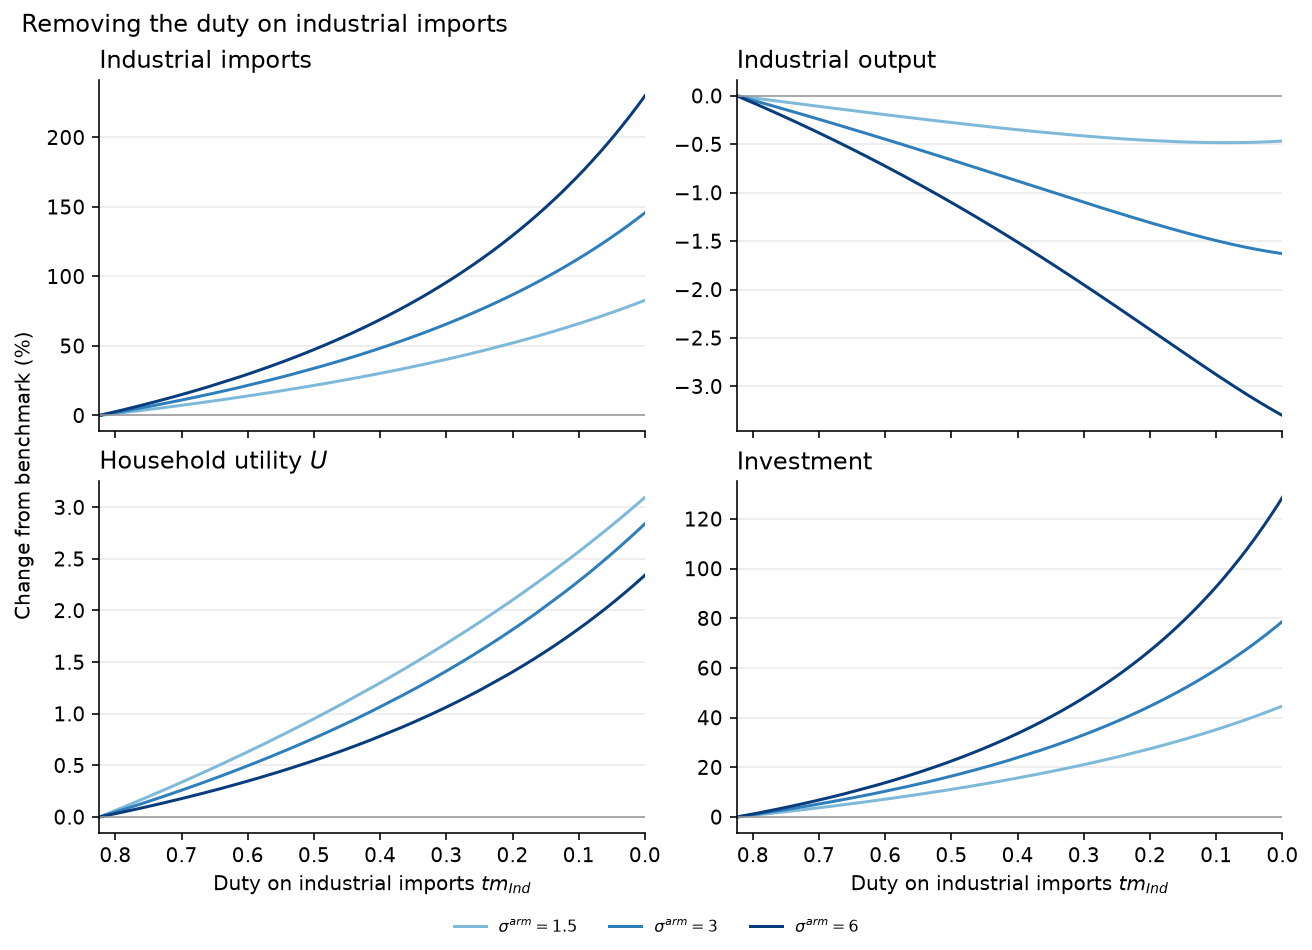

In [18]:
benchmark_duty = float(calibrated_values["tm"][sectors.index("Ind")])
shades = plt.get_cmap("Blues")(np.linspace(0.45, 0.95, len(armington_elasticities)))
elasticity_colors = dict(zip(armington_elasticities, shades, strict=True))
panel_titles = {"imports": "Industrial imports",
                "output": "Industrial output",
                "utility": "Household utility $U$",
                "investment": "Investment"}

fig, axes = plt.subplots(nrows=2,
                         ncols=2,
                         figsize=(9, 6.5),
                         dpi=144,
                         sharex=True,
                         layout="constrained")
for ax, (column, title) in zip(axes.flat, panel_titles.items()):
    for elasticity, path in paths.items():
        ax.plot(path["duty"],
                path[column],
                color=elasticity_colors[elasticity],
                label=rf"$\sigma^{{arm}} = {elasticity:g}$")
    ax.axhline(0.0,
               color="0.6",
               linewidth=0.8)
    ax.set_title(title,
                 loc="left")
    ax.grid(axis="y",
            color="0.92")
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].set_xlim(benchmark_duty, 0.0)
for ax in axes[1]:
    ax.set_xlabel("Duty on industrial imports $tm_{Ind}$")
fig.supylabel("Change from benchmark (%)",
              fontsize=10)
fig.suptitle("Removing the duty on industrial imports",
             x=0.01,
             ha="left")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

In [19]:
pd.DataFrame({elasticity: path.drop(columns="duty").iloc[-1]
              for elasticity, path in paths.items()}).T.rename_axis(index="Armington elasticity").round(2)

,imports,output,utility,investment
Armington elasticity,,,,
1.5,82.82,-0.47,3.10,44.66
3.0,145.74,-1.63,2.84,78.73
6.0,229.89,-3.30,2.34,128.67


The paths for an elasticity of 3 end at the correction's results. Doubling the elasticity to 6 raises industrial imports by 230% instead of 146% and doubles the fall in industrial output, to 3.3%. Halving it to 1.5 gives a rise in imports of 83% and a fall in output of 0.5%. Investment rises more at higher elasticities, by 45% at 1.5 and 129% at 6, because the larger import surge widens the trade deficit and foreign borrowing finances the extra investment. Household utility rises less, by 3.1% at 1.5 and 2.3% at 6.

Every result keeps its sign across the three elasticities, while its size changes by a factor of about 3 for industrial imports and about 7 for industrial output.

## Authors

- Created by Jesse Grabowski, November 26, 2026

## Watermark

In [20]:
%load_ext watermark
%watermark -n -u -v -iv -m -w -p pytensor

Last updated: Thu, 26 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

pytensor: 3.3.8

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

